[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Harshini-Suresha/honeybee-genomics/blob/main/analysis/amfor_analysis.ipynb)

# Genomics of Behaviour in *Apis mellifera*: Amfor analysis
Reproducible computations behind the figures at https://harshini-suresha.github.io/honeybee-genomics/ — real NCBI RefSeq sequences (NM_001011581.1 / XM_026444524.1, Amel_HAv3.1) plus public PKG homologs. Run top to bottom; every section prints and plots its results.

In [1]:
import json, math, re, itertools, urllib.request
from pathlib import Path
from collections import defaultdict
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline

GH = 'https://raw.githubusercontent.com/Harshini-Suresha/honeybee-genomics/main/data'
CANDIDATES = [Path('data'), Path('../data')]
def load(name):
    for d in CANDIDATES:
        p = d / name
        if p.exists():
            return p.read_bytes()
    print(f'downloading {name} from GitHub…')
    return urllib.request.urlopen(f'{GH}/{name}', timeout=60).read()

print('numpy', np.__version__, '| matplotlib', matplotlib.__version__)

numpy 2.1.3 | matplotlib 3.10.0


## 1. Sequences: parse, translate, verify
The page embeds the real RefSeq CDS. We verify length, GC and translation against the known reference protein (678 aa).

In [2]:
BS = 'TCAG'
AAS = 'FFLLSSSSYY**CC*WLLLLPPPPHHQQRRRRIIIMTTTTNNKKSSRRVVVVAAAADDEEGGGG'
CODONS = [a + b + c for a in BS for b in BS for c in BS]
CD = dict(zip(CODONS, AAS))

def parse_fasta(raw):
    recs = {}
    for part in raw.decode().strip().split('>')[1:]:
        lines = part.strip().split('\n')
        recs[lines[0].split()[0]] = ''.join(lines[1:])
    return recs

ref_dna = ''.join(parse_fasta(load('amfor_ref_CDS.fasta'))['NM_001011581.1'].split()) if False else None
# robust: take sequence lines regardless of header
def first_seq(raw):
    lines = raw.decode().strip().split('\n')
    return ''.join(l.strip() for l in lines[1:] if set(l.strip()) <= set('ACGTN'))
ref_dna = first_seq(load('amfor_ref_CDS.fasta'))
x3_dna = first_seq(load('amfor_x3_CDS.fasta'))

def translate(s):
    return ''.join(CD[s[i:i+3]] for i in range(0, len(s) - 2, 3)).rstrip('*')

Pref, Px3 = translate(ref_dna), translate(x3_dna)
gc = lambda s: sum(1 for b in s if b in 'GC') / len(s)
print(f'ref CDS {len(ref_dna)} bp, GC {gc(ref_dna):.2%}, protein {len(Pref)} aa')
print(f'X3  CDS {len(x3_dna)} bp, GC {gc(x3_dna):.2%}, protein {len(Px3)} aa')
print('ref start:', Pref[:12], '| X3 start:', Px3[:12])

ref CDS 2037 bp, GC 47.13%, protein 678 aa
X3  CDS 2025 bp, GC 46.22%, protein 674 aa
ref start: MGTLRELQELLR | X3 start: MDSIRDLKRLLY


## 2. Pairwise protein identity (Needleman–Wunsch)
Global alignments (match +2, mismatch −1, gap −2 — same scoring as the page's sequence lab), % identical columns including gaps.

pairwise % identity:
           Dmel  Nasonia  Amel X3 Amel ref   Bombus
   Dmel   100.0    57.1    55.4    55.2    55.8
Nasonia    57.1   100.0    76.7    74.4    80.1
Amel X3    55.4    76.7   100.0    86.7    90.0
Amel ref    55.2    74.4    86.7   100.0    90.0
 Bombus    55.8    80.1    90.0    90.0   100.0


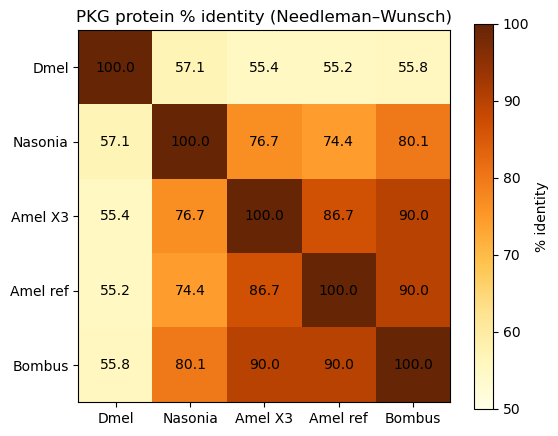

In [3]:
from array import array
def nw(a, b):
    n, m = len(a), len(b)
    S = [array('h', [0]) * (m + 1) for _ in range(n + 1)]
    for i in range(1, n + 1): S[i][0] = -2 * i
    for j in range(1, m + 1): S[0][j] = -2 * j
    for i in range(1, n + 1):
        ai, row, prow = a[i-1], S[i], S[i-1]
        for j in range(1, m + 1):
            sc = 2 if ai == b[j-1] else -1
            v = prow[j-1] + sc
            d1, d2 = prow[j] - 2, row[j-1] - 2
            if d1 > v: v = d1
            if d2 > v: v = d2
            row[j] = v
    i, j, x, y = n, m, [], []
    while i > 0 or j > 0:
        if i > 0 and j > 0 and S[i][j] == S[i-1][j-1] + (2 if a[i-1] == b[j-1] else -1):
            x.append(a[i-1]); y.append(b[j-1]); i -= 1; j -= 1
        elif i > 0 and S[i][j] == S[i-1][j] - 2:
            x.append(a[i-1]); y.append('-'); i -= 1
        else:
            x.append('-'); y.append(b[j-1]); j -= 1
    return ''.join(reversed(x)), ''.join(reversed(y))

hom = {}
for hdr, seq in parse_fasta(load('amfor_homologs.fasta')).items():
    hom[hdr] = seq
SHORT = {'Amel_ref_NP_001011581': 'Amel ref', 'Amel_X3_XM_026444524': 'Amel X3',
         'Bombus_ACS36224': 'Bombus', 'Nasonia_A0A7M7GDM4': 'Nasonia', 'Dmel_P32023_for': 'Dmel'}
ORDER = ['Dmel_P32023_for', 'Nasonia_A0A7M7GDM4', 'Amel_X3_XM_026444524',
         'Amel_ref_NP_001011581', 'Bombus_ACS36224']
assert set(ORDER) <= set(hom), 'homolog FASTA mismatch'
ALN = {}
CANON = ['Amel_ref_NP_001011581', 'Amel_X3_XM_026444524', 'Bombus_ACS36224',
         'Nasonia_A0A7M7GDM4', 'Dmel_P32023_for']
for i in range(len(CANON)):
    ALN[(CANON[i], CANON[i])] = (hom[CANON[i]], hom[CANON[i]])
    for j in range(i + 1, len(CANON)):
        a, b = CANON[i], CANON[j]
        x, y = nw(hom[a], hom[b])
        ALN[(a, b)] = (x, y)
        ALN[(b, a)] = (y, x)  # transpose: rows follow key order
IDENT = {k: sum(1 for x, y in zip(*v) if x == y) / len(v[0]) for k, v in ALN.items()}
M = np.array([[IDENT[(a, b)] * 100 for b in ORDER] for a in ORDER])
print('pairwise % identity:')
print('       ' + ' '.join(f'{SHORT[k]:>8s}' for k in ORDER))
for k, row in zip(ORDER, M):
    print(f'{SHORT[k]:>7s}' + ''.join(f'{v:8.1f}' for v in row))

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(M, vmin=50, vmax=100, cmap='YlOrBr')
ax.set_xticks(range(5), [SHORT[k] for k in ORDER])
ax.set_yticks(range(5), [SHORT[k] for k in ORDER])
for i in range(5):
    for j in range(5):
        ax.text(j, i, f'{M[i, j]:.1f}', ha='center', va='center')
ax.set_title('PKG protein % identity (Needleman–Wunsch)')
fig.colorbar(im, ax=ax, label='% identity')
plt.show()

## 3. UPGMA tree → Newick
Average-linkage clustering on distance = 1 − identity. Teaching-grade (the page notes: replace with RAxML/MEGA + bootstraps).

In [4]:
members = {k: [k] for k in ORDER}
height = {}
labels = list(ORDER)
newick = {k: k for k in ORDER}
while len(labels) > 1:
    best, bestd = None, 1e9
    for i in range(len(labels)):
        for j in range(i + 1, len(labels)):
            a, b = labels[i], labels[j]
            d = sum(1 - IDENT[(x, y)] for x in members[a] for y in members[b]) / (len(members[a]) * len(members[b]))
            if d < bestd:
                bestd, best = d, (a, b)
    a, b = best
    h = bestd / 2
    nid = f'N{len(members)}'
    newick[nid] = f"({newick[a]}:{h - height.get(a, 0):.4f},{newick[b]}:{h - height.get(b, 0):.4f})"
    members[nid] = members[a] + members[b]
    height[nid] = h
    labels = [l for l in labels if l not in (a, b)] + [nid]
tree = newick[labels[0]] + ';'
print(tree)
print('topology check: Bombus closest to Amel ref, Dmel outgroup')

(Dmel_P32023_for:0.2207,(Nasonia_A0A7M7GDM4:0.1147,(Amel_X3_XM_026444524:0.0583,(Amel_ref_NP_001011581:0.0500,Bombus_ACS36224:0.0500):0.0083):0.0565):0.1059);
topology check: Bombus closest to Amel ref, Dmel outgroup


## 4. Codon usage (RSCU): reference vs isoform X3
RSCU = observed codon count / expected under uniform synonymous use, from the real CDS.

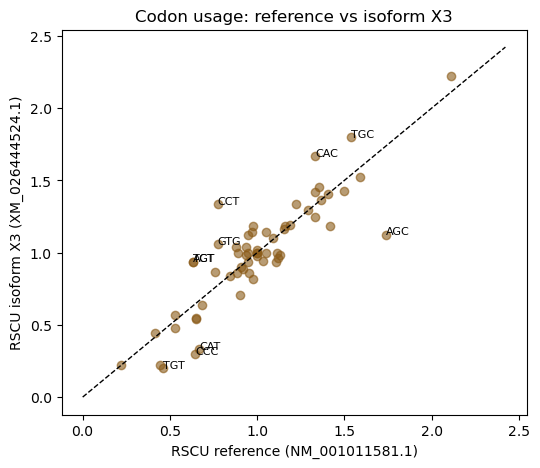

In [5]:
def counts(s):
    m = {}
    for i in range(0, len(s) - 2, 3):
        k = s[i:i+3]
        if CD[k] == '*':
            break
        m[k] = m.get(k, 0) + 1
    return m

def rscu(m):
    tot, deg = defaultdict(int), defaultdict(int)
    for k, c in m.items():
        tot[CD[k]] += c
    for k in CODONS:
        if CD[k] != '*':
            deg[CD[k]] += 1
    return {k: (m.get(k, 0) / tot[CD[k]] * deg[CD[k]] if tot[CD[k]] else 0) for k in CODONS if CD[k] != '*'}

C0, C1 = counts(ref_dna), counts(x3_dna)
R0, R1 = rscu(C0), rscu(C1)
mx = max(max(R0.values()), max(R1.values()))
fig, ax = plt.subplots(figsize=(6, 5))
xs = [R0[c] for c in R0]
ys = [R1[c] for c in R0]
ax.scatter(xs, ys, c='#8A5A17', alpha=0.6)
ax.plot([0, mx + 0.2], [0, mx + 0.2], 'k--', lw=1)
for c in R0:
    if abs(R0[c] - R1[c]) >= 0.25:
        ax.annotate(c, (R0[c], R1[c]), fontsize=8)
ax.set_xlabel('RSCU reference (NM_001011581.1)')
ax.set_ylabel('RSCU isoform X3 (XM_026444524.1)')
ax.set_title('Codon usage: reference vs isoform X3')
plt.show()

## 5. Sliding-window dN/dS (Nei–Gojobori 1986)
Codon alignment via back-translation of the protein alignment; 30-codon windows, Jukes–Cantor correction. Genome-wide purifying selection is expected (ω < 1).

126 windows, mean omega 0.207 (purifying selection)


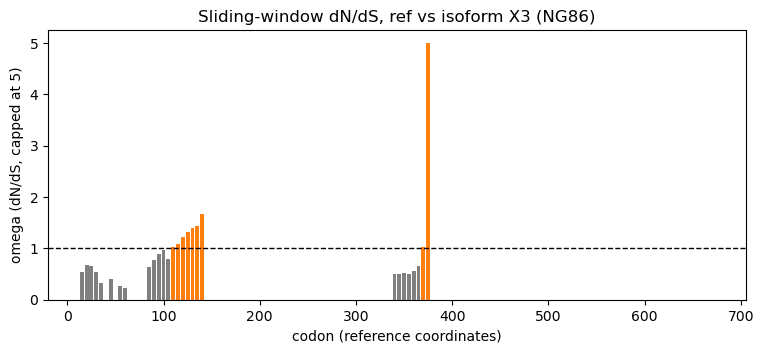

In [6]:
def sites(c):
    s = n = 0.0
    for pos in range(3):
        syn = sum(1 for b in 'TCAG' if b != c[pos] and CD[c[:pos] + b + c[pos+1:]] == CD[c])
        s += syn / 3
        n += 1 - syn / 3
    return s, n

def diff_class(c1, c2):
    if c1 == c2 or '---' in (c1, c2):
        return (0, 0)
    d = [i for i in range(3) if c1[i] != c2[i]]
    if len(d) == 1:
        return (1, 0) if CD[c1] == CD[c2] else (0, 1)
    ts = tn = cnt = 0
    for order in itertools.permutations(d):
        a = list(c1)
        s = n = 0
        for p in order:
            old = ''.join(a)
            a[p] = c2[p]
            if CD[old] == CD[''.join(a)]:
                s += 1
            else:
                n += 1
        ts += s
        tn += n
        cnt += 1
    return (ts / cnt, tn / cnt)

def ng86(pairs):
    S = N = sd = nd = 0.0
    for c1, c2 in pairs:
        if '---' in (c1, c2):
            continue
        s1, n1 = sites(c1)
        s2, n2 = sites(c2)
        S += (s1 + s2) / 2
        N += (n1 + n2) / 2
        a, b = diff_class(c1, c2)
        sd += a
        nd += b
    if S == 0 or N == 0:
        return None
    pS, pN = sd / S, nd / N
    if pS >= 0.75 or pN >= 0.75:
        return None
    dS = -0.75 * math.log(1 - 4 * pS / 3) if pS > 0 else 0.0
    dN = -0.75 * math.log(1 - 4 * pN / 3) if pN > 0 else 0.0
    return (dN / dS if dS > 0 else (9.99 if dN > 0 else 0.0), dN, dS)

x, y = ALN[('Amel_ref_NP_001011581', 'Amel_X3_XM_026444524')]
cod0 = [ref_dna[i:i+3] for i in range(0, len(ref_dna) - 2, 3)]
cod1 = [x3_dna[i:i+3] for i in range(0, len(x3_dna) - 2, 3)]
A0, A1, i0, i1 = [], [], 0, 0
for a, b in zip(x, y):
    A0.append('---' if a == '-' else cod0[i0]); i0 += a != '-'
    A1.append('---' if b == '-' else cod1[i1]); i1 += b != '-'
pairs = list(zip(A0, A1))
wins = []
for s in range(0, len(pairs) - 29, 5):
    seg = pairs[s:s+30]
    if sum(1 for c1, c2 in seg if '---' not in (c1, c2)) < 20:
        continue
    r = ng86(seg)
    if r:
        wins.append((s + 15, min(r[0], 5), r[1], r[2]))
om = [w[1] for w in wins]
print(f'{len(wins)} windows, mean omega {sum(om)/len(om):.3f} (purifying selection)')
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar([w[0] for w in wins], om, width=4, color=['tab:orange' if v > 1 else 'grey' for v in om])
ax.axhline(1, color='k', ls='--', lw=1)
ax.set_xlabel('codon (reference coordinates)')
ax.set_ylabel('omega (dN/dS, capped at 5)')
ax.set_title('Sliding-window dN/dS, ref vs isoform X3 (NG86)')
plt.show()

## 6. PCoA of protein distances
Classical multidimensional scaling on the 1 − identity matrix.

PC1 75.6%, PC2 18.8%


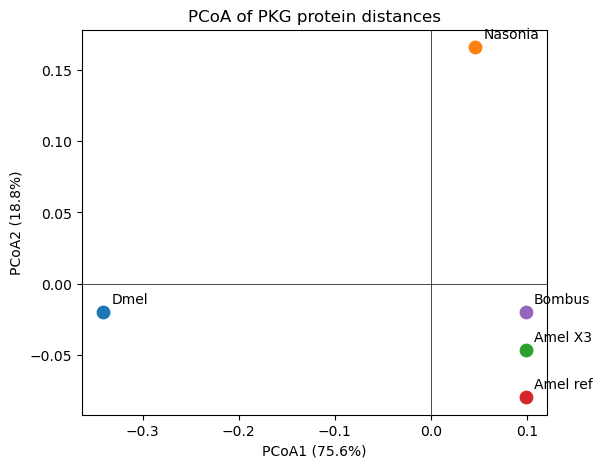

In [7]:
names = ORDER
Dmat = np.array([[1 - IDENT[(a, b)] for b in names] for a in names])
n = len(names)
J = np.eye(n) - np.ones((n, n)) / n
B = -0.5 * J @ (Dmat ** 2) @ J
evals, evec = np.linalg.eigh(B)
idx = np.argsort(evals)[::-1]
evals, evec = np.maximum(evals[idx], 0), evec[:, idx]
coords = evec[:, :2] * np.sqrt(evals[:2])
var = evals[:2] / evals.sum()
print(f'PC1 {var[0]:.1%}, PC2 {var[1]:.1%}')
fig, ax = plt.subplots(figsize=(6, 5))
for (px, py), k in zip(coords, names):
    ax.scatter(px, py, s=80)
    ax.annotate(SHORT[k], (px, py), xytext=(6, 6), textcoords='offset points')
ax.axhline(0, color='k', lw=0.5)
ax.axvline(0, color='k', lw=0.5)
ax.set_xlabel(f'PCoA1 ({var[0]:.1%})')
ax.set_ylabel(f'PCoA2 ({var[1]:.1%})')
ax.set_title('PCoA of PKG protein distances')
plt.show()

## 7. Domains, GC tracks, composition
PROSITE-style pattern scan on the real proteins (not InterProScan), GC1/2/3 + skew, and amino-acid composition.

cNMP       Dmel:429 Nasonia:273 Amel X3:170 Amel ref:165 Bombus:164
Gly-rich   Dmel:630 Nasonia:473 Amel X3:370 Amel ref:374 Bombus:364
Catalytic  Dmel:745 Nasonia:588 Amel X3:485 Amel ref:489 Bombus:479
DFG        Dmel:764 Nasonia:607 Amel X3:504 Amel ref:508 Bombus:498
APE        Dmel:789 Nasonia:632 Amel X3:529 Amel ref:533 Bombus:523


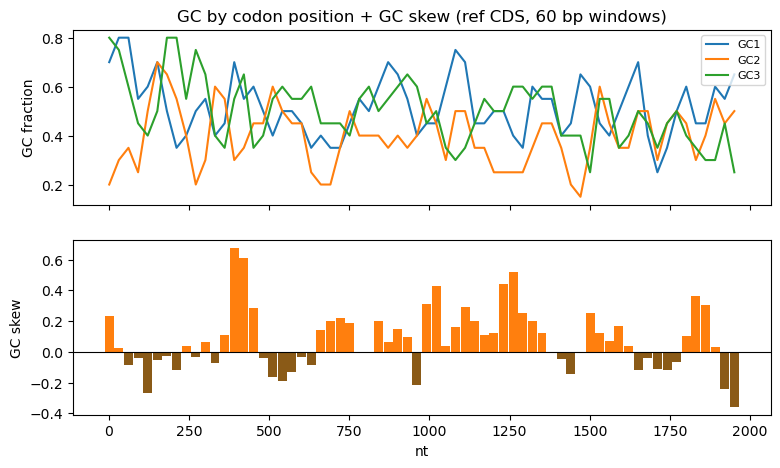

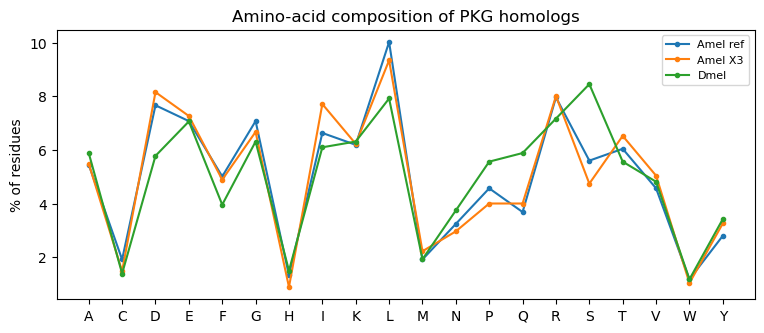

In [8]:
pats = {'cNMP': r'[FVL]GE[LMF]A[IL]', 'Gly-rich': r'G.G.FG.V', 'Catalytic': r'[HY]RDLKP[EQ]N',
        'DFG': r'[VI]DFG.A', 'APE': r'APE[VI][ILV]'}
for pn, pat in pats.items():
    hits = []
    for k in ORDER:
        m = re.search(pat, hom[k])
        hits.append(f'{SHORT[k]}:{m.start()+1}' if m else f'{SHORT[k]}:—')
    print(f'{pn:10s}', ' '.join(hits))

def winstats(s, w=60, st=30):
    out = []
    for i in range(0, len(s) - w + 1, st):
        u = s[i:i+w]
        g = [sum(1 for k in range(o, w, 3) if u[k] in 'GC') / (w / 3) for o in range(3)]
        G, C = u.count('G'), u.count('C')
        out.append((i + 1, *g, (G - C) / (G + C) if G + C else 0))
    return out

W = winstats(ref_dna)
fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
for k, lab in [(1, 'GC1'), (2, 'GC2'), (3, 'GC3')]:
    a1.plot([u[0] for u in W], [u[k] for u in W], label=lab)
a1.set_ylabel('GC fraction')
a1.legend(fontsize=8)
a1.set_title('GC by codon position + GC skew (ref CDS, 60 bp windows)')
a2.bar([u[0] for u in W], [u[4] for u in W], width=28,
       color=['tab:orange' if u[4] >= 0 else '#8A5A17' for u in W])
a2.axhline(0, color='k', lw=0.8)
a2.set_ylabel('GC skew')
a2.set_xlabel('nt')
plt.show()

AAs = 'ACDEFGHIKLMNPQRSTVWY'
comp = {SHORT[k]: [sum(1 for z in hom[k] if z == a) / len(hom[k]) * 100 for a in AAs] for k in ORDER}
fig, ax = plt.subplots(figsize=(9, 3.5))
X = np.arange(20)
for k in ['Amel ref', 'Amel X3', 'Dmel']:
    ax.plot(X, comp[k], marker='o', ms=3, label=k)
ax.set_xticks(X, list(AAs))
ax.set_ylabel('% of residues')
ax.set_title('Amino-acid composition of PKG homologs')
ax.legend(fontsize=8)
plt.show()

## 8. Gene model (Amfor locus, Amel_HAv3.1)
Exon/CDS joins from GenBank NC_037650.1 (GeneID 406092); both RefSeq isoforms share the nine 3′ exons and differ at the 5′ end.

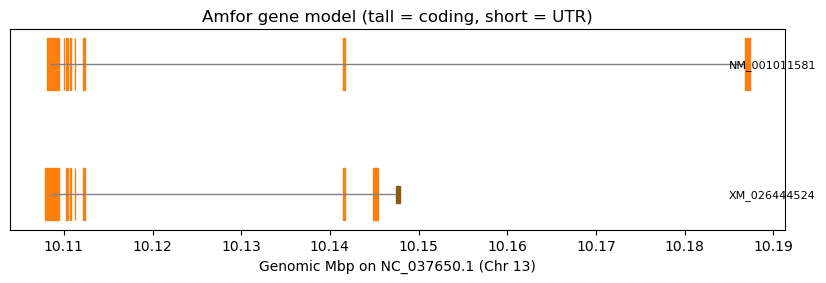

Done — all figures reproduced from real data.


In [9]:
gm = json.loads(load('gene_model.json'))['transcripts']
G2Mb = lambda p: (10189000 - p + 1) / 1e6
fig, ax = plt.subplots(figsize=(10, 2.6))
for yi, tid in enumerate(['NM_001011581.1', 'XM_026444524.1']):
    E = gm[tid]['exons_slice']
    C = gm[tid]['cds_slice']
    y = 1 - yi * 0.45
    ax.hlines(y, G2Mb(E[-1][0]), G2Mb(E[0][1]), colors='grey', lw=1)
    for s, e in E:
        g1, g2 = G2Mb(e), G2Mb(s)
        coding = any(not (c[1] < s or c[0] > e) for c in C)
        ax.add_patch(plt.Rectangle((g1, y - (0.09 if coding else 0.03)), g2 - g1,
                                   0.18 if coding else 0.06,
                                   color='tab:orange' if coding else '#8A5A17'))
    ax.text(10.185, y, tid.split('.')[0], va='center', fontsize=8)
ax.set_xlabel('Genomic Mbp on NC_037650.1 (Chr 13)')
ax.set_yticks([])
ax.set_title('Amfor gene model (tall = coding, short = UTR)')
plt.show()
print('Done — all figures reproduced from real data.')

## 9. Maximum-likelihood tree (IQ-TREE 2.4.0)
MAFFT alignment (`data/amfor_msa_MAFFT.fasta`, 974 columns), ModelFinder best-fit **JTT+I+R2** (BIC), 1000 ultrafast bootstraps, rooted on *Drosophila*. This is the tree shown on the page.

(Amel_ref:0.0820178390,(Amel_X3:0.1341114464,(Bombus:0.0145952594,Nasonia:0.1008909399)90:0.0255714720)61:0.0355385896,Dmel:1.2256683146);


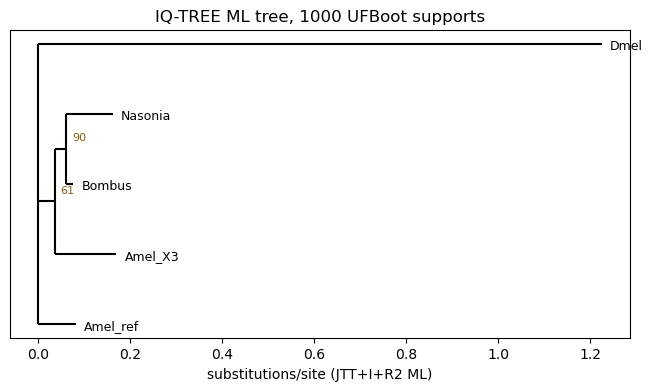

In [10]:
import re
nwk = load('tree_ml_iqtree.contree').decode().strip()
print(nwk)

# tiny Newick parser -> (name, branch, support, children)
def parse(s):
    s = s.strip().rstrip(';')
    def node(i):
        if s[i] == '(':
            i += 1
            kids = []
            while True:
                k, i = node(i)
                kids.append(k)
                if s[i] == ',':
                    i += 1
                else:
                    break
            assert s[i] == ')'
            i += 1
            m = re.match(r'(\d+)?(?::([0-9.eE+-]+))?', s[i:])
            sup = float(m.group(1)) if m and m.group(1) else None
            br = float(m.group(2)) if m and m.group(2) else 0.0
            i += len(m.group(0)) if m else 0
            return {'n': None, 'b': br, 's': sup, 'k': kids}, i
        else:
            m = re.match(r'([^:,()]+):([0-9.eE+-]+)', s[i:])
            i += len(m.group(0))
            return {'n': m.group(1), 'b': float(m.group(2)), 's': None, 'k': []}, i
    t, i = node(0)
    return t

T = parse(nwk)
leaves = []
# assign y by leaf order, x = distance from root
order, ymap = [], {}
def walk(t, x=0.0):
    if not t['k']:
        ymap[t['n']] = len(order)
        order.append(t['n'])
        t['x'], t['y'] = x, len(order) - 1
        return
    for k in t['k']:
        walk(k, x + k['b'])
    ys = [c['y'] for c in t['k']]
    t['x'], t['y'] = x, sum(ys) / len(ys)

walk(T)
fig, ax = plt.subplots(figsize=(8, 4))
def draw(t):
    if t['k']:
        ys = [c['y'] for c in t['k']]
        ax.vlines(t['x'], min(ys), max(ys), colors='k')
        for c in t['k']:
            ax.hlines(c['y'], t['x'], c['x'], colors='k')
            if c['s']:
                ax.annotate(f'{c["s"]:.0f}', (c['x'], c['y']), xytext=(4, 6),
                            textcoords='offset points', fontsize=8, color='#8A5A17')
            draw(c)
    else:
        ax.annotate(t['n'], (t['x'], t['y']), xytext=(6, -4),
                    textcoords='offset points', fontsize=9)
draw(T)
ax.set_xlabel('substitutions/site (JTT+I+R2 ML)')
ax.set_yticks([])
ax.set_title('IQ-TREE ML tree, 1000 UFBoot supports')
plt.show()

## 10. InterPro domains (via UniProt)
`A0ACM8PXT7` is the exact 678 aa equivalent of NP_001011581.1; its features carry InterPro accessions. X3 coordinates come from mapping through the ref-vs-X3 alignment (see §5 code path).

UniProt domain features:
  Domain       102-217  Cyclic nucleotide-binding
  Domain       220-335  Cyclic nucleotide-binding
  Domain       367-626  Protein kinase
  Domain       627-678  AGC-kinase C-terminal
  Region       102-217  cNMP-binding domain
  Region       220-335  cNMP-binding domain
  Region       643-678  Disordered
  Active site  491-491  Proton acceptor
  Binding site 373-381  
  Binding site 397-397  

InterPro entries:
  IPR000961  AGC-kinase_C
  IPR002374  cGMP_dep_kinase
  IPR018488  cNMP-bd_CS
  IPR000595  cNMP-bd_dom
  IPR018490  cNMP-bd_dom_sf
  IPR011009  Kinase-like_dom_sf
  IPR031831  PKcGMP_CC
  IPR000719  Prot_kinase_dom
  IPR017441  Protein_kinase_ATP_BS
  IPR014710  RmlC-like_jellyroll
  IPR008271  Ser/Thr_kinase_AS
  IPR035014  STKc_cGK


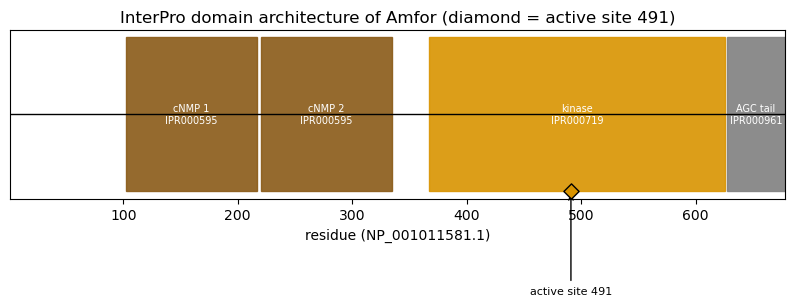

In [11]:
ud = json.loads(urllib.request.urlopen(
    'https://rest.uniprot.org/uniprotkb/A0ACM8PXT7.json', timeout=30).read().decode())
print('UniProt domain features:')
for f in ud.get('features', []):
    loc = f.get('location', {})
    print(f"  {f.get('type'):12s} {loc.get('start', {}).get('value')}-{loc.get('end', {}).get('value')}  {(f.get('description') or '')[:60]}")
print('\nInterPro entries:')
for x in ud.get('uniProtKBCrossReferences', []):
    if x.get('database') == 'InterPro':
        props = x.get('properties', [])
        print(f"  {x.get('id')}  {props[0].get('value') if props else ''}")
fig, ax = plt.subplots(figsize=(10, 2.2))
doms = [(102, 217, 'cNMP 1\nIPR000595', '#8A5A17'), (220, 335, 'cNMP 2\nIPR000595', '#8A5A17'),
        (367, 626, 'kinase\nIPR000719', '#D99400'), (627, 678, 'AGC tail\nIPR000961', 'grey')]
ax.hlines(0.5, 1, 678, colors='k', lw=1)
for s, e, lab, col in doms:
    ax.add_patch(plt.Rectangle((s, 0.32), e - s, 0.36, color=col, alpha=0.9))
    ax.annotate(lab, ((s + e) / 2, 0.5), ha='center', va='center', fontsize=7, color='white')
ax.annotate('active site 491', xy=(491, 0.32), xytext=(491, 0.08), ha='center', fontsize=8,
            arrowprops=dict(arrowstyle='->', color='k'))
ax.scatter([491], [0.32], s=60, marker='D', color='#D99400', edgecolors='k', zorder=5)
ax.set_xlim(1, 678)
ax.set_yticks([])
ax.set_xlabel('residue (NP_001011581.1)')
ax.set_title('InterPro domain architecture of Amfor (diamond = active site 491)')
plt.show()